In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from pathlib import Path
import json
import sqlite3

In [2]:
RESULTS = Path("../results/benchmark_10-25-26")
STAGES  = {"decode", "preprocess", "encode", "project"}

In [3]:
def to_wide(long, run_name, stages=STAGES):
    return (
        long.pivot_table(index=["batch_size", "iter"], columns="stage",
                         values="duration_ms")
            .reindex(columns=[s for s in stages if s in set(long["stage"])])
            .rename(columns=lambda s: f"{s}_ms")
            .reset_index()
            .assign(run=run_name)
    )


def load_run(run_dir, stages=STAGES, wide=True):
    run_dir = Path(run_dir)

    frames = []
    for stage in stages:
        csv = run_dir / f"{stage}.csv"

        if not csv.exists():
            continue

        df = pd.read_csv(csv)
        df["stage"] = stage
        frames.append(df)

    long = pd.concat(frames, ignore_index=True)

    return to_wide(long, run_dir.name, stages) if wide else long.assign(run=run_dir.name)

In [4]:
nsys_df = load_run(RESULTS)
nsys_df.head(3)

stage,batch_size,iter,project_ms,decode_ms,encode_ms,preprocess_ms,run
0,1,0,0.544512,9.553746,37.546432,24.170846,benchmark_10-25-26
1,1,1,0.560608,8.721684,39.451714,22.489024,benchmark_10-25-26
2,1,2,0.565024,8.450772,39.308800,21.868961,benchmark_10-25-26


In [5]:
nsys_db = RESULTS / "nsys_capture.sqlite"

QUERY = """
SELECT text AS name, start, end, globalTid
FROM NVTX_EVENTS
WHERE eventType = 59          -- NvtxPushPopRange
  AND text LIKE '%/bs=%'
ORDER BY start
"""

with sqlite3.connect(nsys_db) as conn:
    nvtx_df = pd.read_sql_query(QUERY, conn)

nvtx_df["duration_ms"] = (nvtx_df["end"] - nvtx_df["start"]) / 1e6

## Same name format as push() in run_nvidia.py: "<stage>/bs=<n>"
nvtx_df[["stage", "batch_size"]] = nvtx_df["name"].str.extract(r"^(\w+)/bs=(\d+)$")
nvtx_df["batch_size"] = nvtx_df["batch_size"].astype(int)

## iter = position within its (batch_size, stage) group, since the range name
## carries no index -- works because the rows are sorted by start
nvtx_df["iter"] = nvtx_df.groupby(["batch_size", "stage"]).cumcount()

nvtx_df.head(10)

,name,start,end,globalTid,duration_ms,stage,batch_size,iter
0,subtest/bs=1,9129672192,17997501696,313087917604982,8867.829504,subtest,1,0
1,iter/bs=1,9129732448,9201021920,313087917604982,71.289472,iter,1,0
2,decode/bs=1,9129735040,9139946496,313087917604982,10.211456,decode,1,0
3,preprocess/bs=1,9139975744,9164048544,313087917604982,24.072800,preprocess,1,0
4,encode/bs=1,9164076480,9200586592,313087917604982,36.510112,encode,1,0
5,project/bs=1,9200606592,9201018272,313087917604982,0.411680,project,1,0
6,iter/bs=1,9201036224,9269776480,313087917604982,68.740256,iter,1,1
7,decode/bs=1,9201038656,9210204416,313087917604982,9.165760,decode,1,1
8,preprocess/bs=1,9210233088,9232481984,313087917604982,22.248896,preprocess,1,1
9,encode/bs=1,9232510112,9269256608,313087917604982,36.746496,encode,1,1


In [6]:
## drops the iter/subtest wrapper ranges, at every batch size
nvtx_df = nvtx_df[nvtx_df["stage"].isin(STAGES)].copy()

nvtx_df.head(5)

,name,start,end,globalTid,duration_ms,stage,batch_size,iter
2,decode/bs=1,9129735040,9139946496,313087917604982,10.211456,decode,1,0
3,preprocess/bs=1,9139975744,9164048544,313087917604982,24.072800,preprocess,1,0
4,encode/bs=1,9164076480,9200586592,313087917604982,36.510112,encode,1,0
5,project/bs=1,9200606592,9201018272,313087917604982,0.411680,project,1,0
7,decode/bs=1,9201038656,9210204416,313087917604982,9.165760,decode,1,1


In [7]:
nvtx_wide = to_wide(nvtx_df, "nvtx")
nvtx_wide.head(3)

stage,batch_size,iter,project_ms,decode_ms,encode_ms,preprocess_ms,run
0,1,0,0.411680,10.211456,36.510112,24.072800,nvtx
1,1,1,0.496960,9.165760,36.746496,22.248896,nvtx
2,1,2,0.406944,9.089664,36.111520,24.998592,nvtx


C:\Users\Travis\AppData\Local\Temp\ipykernel_16544\925621711.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


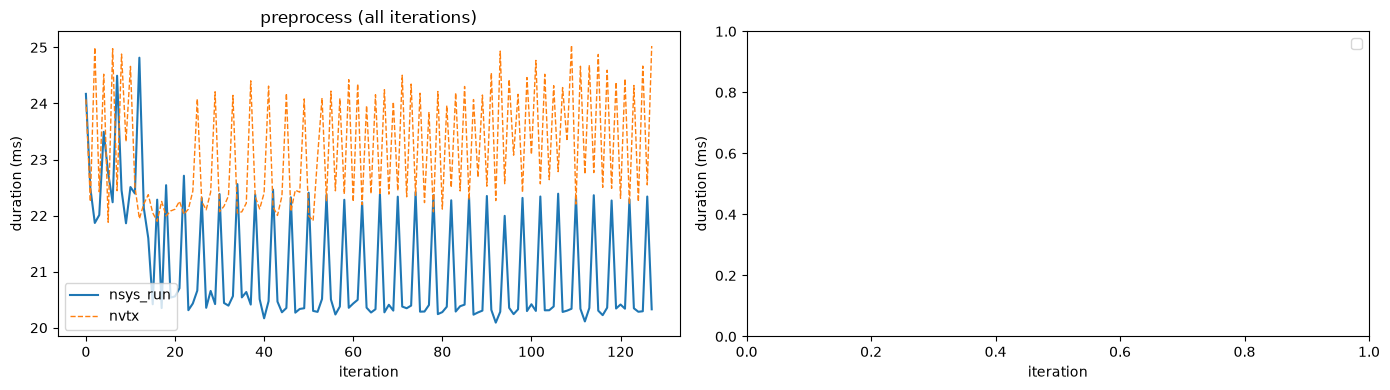

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(nsys_df["iter"], nsys_df["preprocess_ms"], label="nsys_run", linewidth=1.5)
ax1.plot(nvtx_wide["iter"], nvtx_wide["preprocess_ms"], label="nvtx", linewidth=1.0, linestyle="--")
ax1.set_title("preprocess (all iterations)")

for ax in (ax1, ax2):
    ax.set_xlabel("iteration")
    ax.set_ylabel("duration (ms)")
    ax.legend()

plt.tight_layout()
plt.show()